# **DS2026 DELIVERABLE 1: THE HOUSE ALWAYS WINS**
**Gaayathri Mathuria**

### The Martingale strategy

If you've ever played roulette, you've probably heard about the Martingale strategy. In this strategy, a player bets on one color (say, black) and spins. If the wheel lands on black, the player spins again with the initial bet. If it lands on red or green, the player doubles their previous bet and spins again. If the player wins after a loss, their initial bet resets to the first value.

The spinning stops when the player either has:
1. \\$W (total money at which player withdraws)
2. \\$0 (they run through their starting budget, B, and can't wager more than they have)
3. The player completes L spins/wagers/plays

The casino might also have a max wager, M, and the player cannot wager beyond this.

On a standard wheel, there are 38 pockets: 18 red, 18 black, and 2 green. If a player wins, they profit what they wagered, and if they lose, the loss is also equal to the wager.

Here's an example:

I bet \\$1 on black and spin black, so my earnings are \\$1. I then bet \\$1 on black again and spin red, so my earnings are \\$0 (I lose the dollar I just earned). Then, I bet \\$2 on black, spin black, and end the game with \\$2 in earnings.

Now, as I'm sure you're thinking, this strategy sounds quite profitable. Hypothetically, since in a sequence of losses there eventually has to be at least one win, a player could just continue this strategy and stop at a win they're satisfied with.

### Is this strategy actually profitable in real life?

To answer this question, let's first simulate one visit to the casino. The function below is going to calculate the wager for each play, spin a digital roulette wheel, and stop according to the rules mentioned above.

In [43]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from itertools import groupby

def oneplay(B=200, W=300, L=200, M=100, summary=True):
    '''
    function to simulate a single play of roulette using the martingale strategy
    '''
    # martingale
    def wager(ledger):
        '''
        calculates the wager on a given spin using the strategy
        '''
        if ledger["outcome"][-1] == 1:
            new_wager = 1
        else:
            new_wager = min(2*ledger["wager"][-1], M, ledger["budget"][-1]) #picks the smallest out of either the new wager, money left, or max wager
        ledger["wager"].append(new_wager)

    def spin(ledger):
        '''
        simulates a spin using the binomial distribution where the probability of success is 18/38
        '''
        spin = np.random.binomial(1, p=18/38) #18/38 probability of success betting on red or black
        ledger["outcome"].append(spin)

    def stop(ledger):
        '''
        simulates the Martingale stop rule
        '''
        if ledger["outcome"][-1] == 1:
            ledger["budget"].append(ledger["budget"][-1] + ledger["wager"][-1]) #calculating current budget, adding a win
        else:
            ledger["budget"].append(ledger["budget"][-1] - ledger["wager"][-1]) #calculating current budget, subtracting a loss

        if ledger["budget"][-1] >= W:
            outcome = 1      # reached winning threshold
        elif len(ledger["budget"]) - 1 >= L:
            outcome = -1     # stopped after L spins/plays
        elif ledger["budget"][-1] <= 0:
            outcome = -2     # bankrupt
        else:
            outcome = 0
        return outcome

    ledger = {"budget": [B], "wager": [0], "outcome": [1]} #modified the ledger so that len() is counting exactly the number of spins
    
    outcome = 0
    
    while outcome == 0:
        wager(ledger)
        spin(ledger)
        outcome = stop(ledger)

    if summary == False:
        return ledger

    bad_luck = max([len(list(values)) for key, values in groupby(ledger["outcome"]) if key == 0]) #calculates a bad luck streak

    summary = {
          "B": B, "W": W, "L": L, "M": M
        , "outcome": outcome
        , "profit": ledger["budget"][-1] - B
        , "n_games": len(ledger["budget"]) - 1
        , "prop_red": np.mean(ledger["outcome"])
        , "bad_luck_streak": bad_luck
    }
    return summary

### What do a few casino visits look like?

Let's plot one visit as well as five simulated visits (oneplay()) and see what they look like.

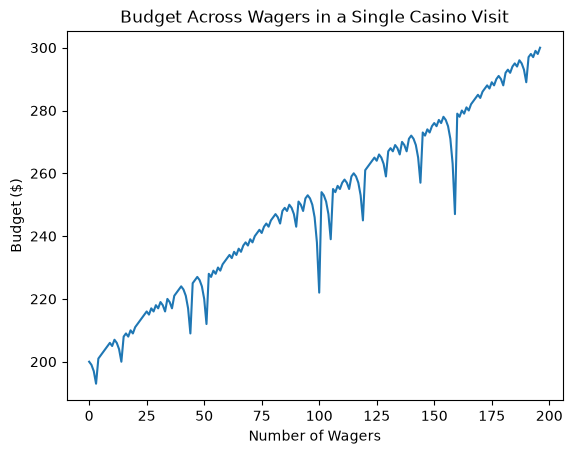

In [44]:
#one visit
np.random.seed(20261025) #setting seed
plt.plot(oneplay(summary=False)['budget']) #changing summary to false so it returns the ledger, plotting budget
plt.xlabel('Number of Wagers')
plt.ylabel('Budget ($)')
plt.title('Budget Across Wagers in a Single Casino Visit')
plt.show()
plt.close()


For one visit, the gambler's budget takes a few drops but ultimately ends up on an upwards trajectory. The visit ends at the $300 winning threshold.

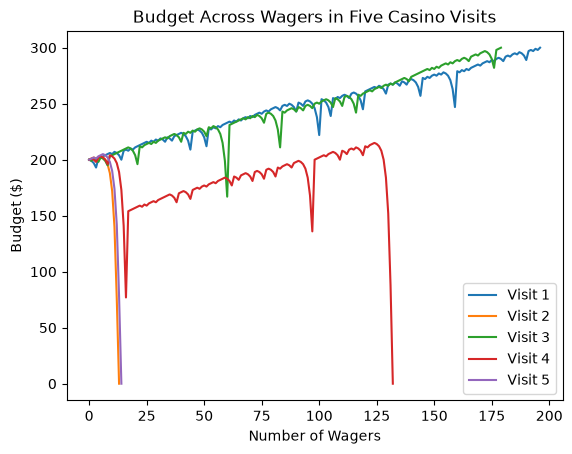

In [45]:
#five visits
np.random.seed(20261025)
for i in range(5):
    p1 = oneplay(summary=False)
    plt.plot(p1["budget"], label=f"Visit {i+1}")
plt.xlabel("Number of Wagers")
plt.ylabel("Budget ($)")
plt.title("Budget Across Wagers in Five Casino Visits")
plt.legend()
plt.show()




For five visits with a $200 starting budget, 3/5 resulted in bankruptcy, with the other two resulting in higher earnings. Two out of the 3 that resulted in bankruptcy resulted in bankruptcy within 25 spins, and the other only after 125. 

### If we simulated a really large number of visits, what would the average winnings look like? What could a gambler expect to earn?

To do this, we can increase the range to 10,000 and simulate a visit for each number in that range. The Law of Large Numbers states that as the number of simulated random trials increase, the average of their results will eventually converge to their true expected value. 10,000 is a pretty big number, so that's why we're using it. Then, we can store the profit from each visit, and calculate the mean of it to get a value for "expected" or average earnings.

In [46]:
np.random.seed(20261025)
A = [oneplay() for i in range(10000)]
profits = [visit["profit"] for visit in A]
print(f"Average Profit: {np.mean(profits)}")

Average Profit: -36.6485


**The average profit with our given parameters is -36.6485.** This means that within the given parameters, the Martingale strategy is not profitable.

### What if we change the parameters? Let's try changing the starting budget.

It seems logical that a player with a bigger budget will win bigger because they're less likely to go bankrupt. However, let's check this hypothesis by simulating 10,000 visits to the casino for each value of the starting budget and then averaging the profit for each. We'll also change W so the function works, but keep the profit at which the player quits ($100) the same.

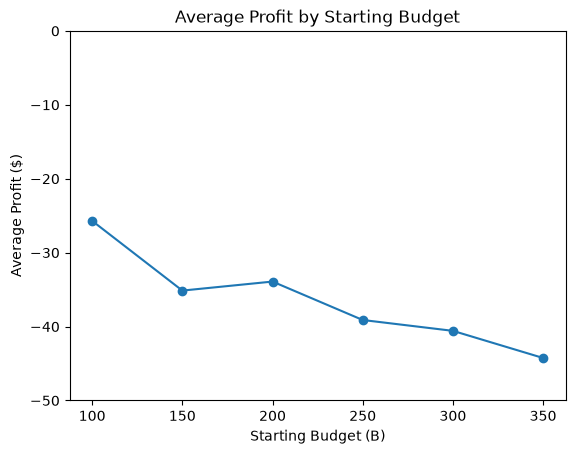

In [47]:
np.random.seed(20261025)
values = [100, 150, 200, 250, 300, 350]
A = [oneplay(B=b, W=b+100) for b in values for i in range(10000)] #need to vary W along with B for function to work
df2 = pd.DataFrame(A)

table = df2.groupby("B").agg(avg_profit=("profit", "mean")).reset_index()

plt.plot(table.B, table.avg_profit, marker="o")
plt.ylim(-50,0)
plt.xlabel("Starting Budget (B)")
plt.ylabel("Average Profit ($)")
plt.title("Average Profit by Starting Budget")
plt.show()

As the budget increases, average profit actually becomes more negative. The chance of losing a single spin stays at 20/38 no matter how large your budget is. If the budget is larger, more money is being wagered in a game that loses around 5.3 cents ((18/38)(+1) + (20/38)(−1) = −2/38 ≈ 5.3) on every dollar. The player goes bankrupt less easily, but every bankruptcy costs the player much more.

### Overall, the Martingale strategy is not actually profitable.

 Martingale might feel like it works, because (assuming an unlimited number of plays) any sequence of plays can be divided into segments that end in a win, and each completed cycle results in profit. However, the edge the house has from green, paired with the fact that a player's budget is limited and they can't bet more than they have if they lose everything in a "bad luck streak", results in large losses. These large losses then weigh down the average value, resulting in a negative expected profit.

## **Ultimately, the house always wins!**